# Supervised Classification / Regression Modeling & Tuning

## Credit Default Risk Prediction

### RabTech Academy AI & ML Internship — Task 4

This project compares multiple supervised machine learning models for credit default prediction.

The project performs:
- Multiple model training
- Hyperparameter optimization
- Stratified K-Fold cross-validation
- Precision, Recall and F1-score evaluation
- ROC-AUC evaluation
- ROC-AUC curve visualization
- Confusion matrix analysis
- Model comparison
- Champion model selection
- Model serialization

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    GridSearchCV
)

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.linear_model import LogisticRegression

from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
df = pd.read_csv("dataset.csv")

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nFirst 5 Rows:")
display(df.head())

Dataset Shape: (30001, 25)

Column Names:
['Unnamed: 0', 'X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'X7', 'X8', 'X9', 'X10', 'X11', 'X12', 'X13', 'X14', 'X15', 'X16', 'X17', 'X18', 'X19', 'X20', 'X21', 'X22', 'X23', 'Y']

First 5 Rows:


,Unnamed: 0,X1,X2,X3,X4,X5,X6,X7,X8,X9,...,X15,X16,X17,X18,X19,X20,X21,X22,X23,Y
0,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
1,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
2,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
3,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
4,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0


In [3]:
print("Dataset Information:")
df.info()

print("\nMissing Values:")
display(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30001 entries, 0 to 30000
Data columns (total 25 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Unnamed: 0  30001 non-null  object
 1   X1          30001 non-null  object
 2   X2          30001 non-null  object
 3   X3          30001 non-null  object
 4   X4          30001 non-null  object
 5   X5          30001 non-null  object
 6   X6          30001 non-null  object
 7   X7          30001 non-null  object
 8   X8          30001 non-null  object
 9   X9          30001 non-null  object
 10  X10         30001 non-null  object
 11  X11         30001 non-null  object
 12  X12         30001 non-null  object
 13  X13         30001 non-null  object
 14  X14         30001 non-null  object
 15  X15         30001 non-null  object
 16  X16         30001 non-null  object
 17  X17         30001 non-null  object
 18  X18         30001 non-null  object
 19  X19         30001 non-nul

Unnamed: 0    0
X1            0
X2            0
X3            0
X4            0
X5            0
X6            0
X7            0
X8            0
X9            0
X10           0
X11           0
X12           0
X13           0
X14           0
X15           0
X16           0
X17           0
X18           0
X19           0
X20           0
X21           0
X22           0
X23           0
Y             0
dtype: int64


Duplicate Rows:
0


In [7]:
# Define target variable
target = "Y"

# Remove the extra index column and target column
X = df.drop(columns=["Unnamed: 0", target])

# Target variable
y = pd.to_numeric(df[target], errors="coerce")

# Remove rows where target is missing
valid_rows = y.notna()

X = X.loc[valid_rows].copy()
y = y.loc[valid_rows].copy()

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

Features shape: (30000, 23)
Target shape: (30000,)

Target distribution:
Y
0.0    23364
1.0     6636
Name: count, dtype: int64


In [8]:
# Define categorical features
categorical_features = [
    "X2",   # SEX
    "X3",   # EDUCATION
    "X4"    # MARRIAGE
]

# All remaining features are numerical
numerical_features = [
    col for col in X.columns
    if col not in categorical_features
]

print("Categorical Features:")
print(categorical_features)

print("\nNumerical Features:")
print(numerical_features)

Categorical Features:
['X2', 'X3', 'X4']

Numerical Features:
['X1', 'X5', 'X6', 'X7', 'X8', 'X9', 'X10', 'X11', 'X12', 'X13', 'X14', 'X15', 'X16', 'X17', 'X18', 'X19', 'X20', 'X21', 'X22', 'X23']


In [9]:
target = "default payment next month"

In [10]:
print("Target name:", target)
print("Target data type:", y.dtype)

print("\nTarget values:")
print(y.value_counts())

print("\nMissing target values:")
print(y.isna().sum())

Target name: default payment next month
Target data type: float64

Target values:
Y
0.0    23364
1.0     6636
Name: count, dtype: int64

Missing target values:
0


In [11]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training data: (24000, 23)
Testing data: (6000, 23)

Training target distribution:
Y
0.0    18691
1.0     5309
Name: count, dtype: int64

Testing target distribution:
Y
0.0    4673
1.0    1327
Name: count, dtype: int64


In [12]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

print("Numerical preprocessing pipeline created.")

Numerical preprocessing pipeline created.


In [13]:
from sklearn.preprocessing import OneHotEncoder

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

print("Categorical preprocessing pipeline created.")

Categorical preprocessing pipeline created.


In [14]:
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse=False
    ))
])

TypeError: OneHotEncoder.__init__() got an unexpected keyword argument 'sparse'

In [15]:
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])

print("ColumnTransformer created successfully.")

ColumnTransformer created successfully.


In [16]:
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("5-Fold Stratified Cross-Validation created.")

5-Fold Stratified Cross-Validation created.


In [17]:
from sklearn.linear_model import LogisticRegression

logistic_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ))
])

print("Logistic Regression pipeline created.")

Logistic Regression pipeline created.


In [18]:
logistic_params = {
    "model__C": [0.1, 1, 10],
    "model__solver": ["liblinear", "lbfgs"]
}

print("Logistic Regression parameter grid:")
print(logistic_params)

Logistic Regression parameter grid:
{'model__C': [0.1, 1, 10], 'model__solver': ['liblinear', 'lbfgs']}


In [19]:
from sklearn.model_selection import GridSearchCV

logistic_grid = GridSearchCV(
    estimator=logistic_pipeline,
    param_grid=logistic_params,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1,
    verbose=1
)

logistic_grid.fit(X_train, y_train)

print("\nBest Logistic Regression Parameters:")
print(logistic_grid.best_params_)

print("\nBest Cross-Validation ROC-AUC:")
print(logistic_grid.best_score_)

Fitting 5 folds for each of 6 candidates, totalling 30 fits

Best Logistic Regression Parameters:
{'model__C': 1, 'model__solver': 'liblinear'}

Best Cross-Validation ROC-AUC:
0.7274851130338768


In [20]:
# Store the best Logistic Regression model

best_logistic_model = logistic_grid.best_estimator_

print("Best Logistic Regression model:")
print(best_logistic_model)

print("\nBest parameters:")
print(logistic_grid.best_params_)

print("\nBest CV ROC-AUC:")
print(logistic_grid.best_score_)

Best Logistic Regression model:
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['X1', 'X5', 'X6', 'X7', 'X8',
                                                   'X9', 'X10', 'X11', 'X12',
                                                   'X13', 'X14', 'X15', 'X16',
                                                   'X17', 'X18', 'X19', 'X20',
                                                   'X21', 'X22', 'X23']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
       

In [21]:
# Predictions on test data

y_pred_logistic = best_logistic_model.predict(X_test)
y_prob_logistic = best_logistic_model.predict_proba(X_test)[:, 1]

# Calculate metrics
logistic_accuracy = accuracy_score(y_test, y_pred_logistic)
logistic_precision = precision_score(y_test, y_pred_logistic)
logistic_recall = recall_score(y_test, y_pred_logistic)
logistic_f1 = f1_score(y_test, y_pred_logistic)
logistic_roc_auc = roc_auc_score(y_test, y_prob_logistic)

print("Logistic Regression Test Results")
print("--------------------------------")
print("Accuracy :", logistic_accuracy)
print("Precision:", logistic_precision)
print("Recall   :", logistic_recall)
print("F1-Score :", logistic_f1)
print("ROC-AUC  :", logistic_roc_auc)

Logistic Regression Test Results
--------------------------------
Accuracy : 0.6783333333333333
Precision: 0.3678211310828584
Recall   : 0.6322532027128862
F1-Score : 0.46507760532150777
ROC-AUC  : 0.7106001527800602


In [22]:
print("Logistic Regression Classification Report")
print("------------------------------------------")

print(classification_report(
    y_test,
    y_pred_logistic
))

Logistic Regression Classification Report
------------------------------------------
              precision    recall  f1-score   support

         0.0       0.87      0.69      0.77      4673
         1.0       0.37      0.63      0.47      1327

    accuracy                           0.68      6000
   macro avg       0.62      0.66      0.62      6000
weighted avg       0.76      0.68      0.70      6000



In [23]:
cm = confusion_matrix(
    y_test,
    y_pred_logistic
)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[3231 1442]
 [ 488  839]]


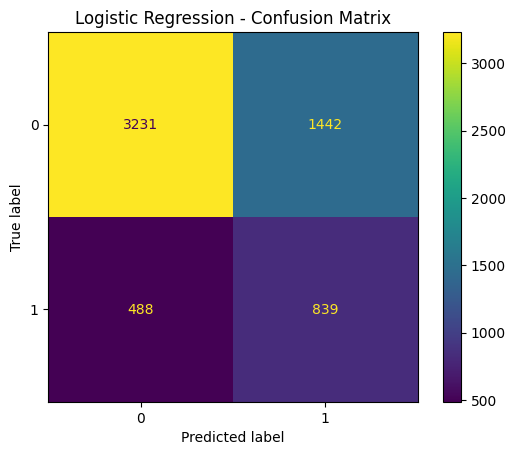

In [24]:
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm
)

disp.plot()
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

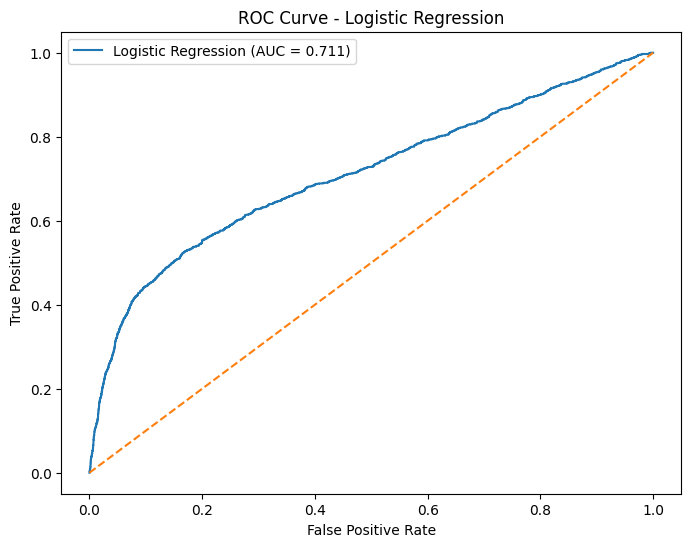

In [25]:
fpr_logistic, tpr_logistic, _ = roc_curve(
    y_test,
    y_prob_logistic
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr_logistic,
    tpr_logistic,
    label=f"Logistic Regression (AUC = {logistic_roc_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Logistic Regression")
plt.legend()
plt.show()

In [26]:
from sklearn.ensemble import RandomForestClassifier

random_forest_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ))
])

print("Random Forest pipeline created successfully.")

Random Forest pipeline created successfully.


In [27]:
random_forest_params = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [10, 20],
    "model__min_samples_split": [2, 5]
}

print("Random Forest parameter grid:")
print(random_forest_params)

Random Forest parameter grid:
{'model__n_estimators': [100, 200], 'model__max_depth': [10, 20], 'model__min_samples_split': [2, 5]}


In [28]:
random_forest_grid = GridSearchCV(
    estimator=random_forest_pipeline,
    param_grid=random_forest_params,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1,
    verbose=1
)

random_forest_grid.fit(X_train, y_train)

print("\nBest Random Forest Parameters:")
print(random_forest_grid.best_params_)

print("\nBest Cross-Validation ROC-AUC:")
print(random_forest_grid.best_score_)

Fitting 5 folds for each of 8 candidates, totalling 40 fits

Best Random Forest Parameters:
{'model__max_depth': 10, 'model__min_samples_split': 5, 'model__n_estimators': 200}

Best Cross-Validation ROC-AUC:
0.7792839580105717


In [33]:
best_random_forest_model = random_forest_grid.best_estimator_

print("Best Random Forest model:")
print(best_random_forest_model)

print("\nBest parameters:")
print(random_forest_grid.best_params_)

print("\nBest CV ROC-AUC:")
print(random_forest_grid.best_score_)

Best Random Forest model:
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['X1', 'X5', 'X6', 'X7', 'X8',
                                                   'X9', 'X10', 'X11', 'X12',
                                                   'X13', 'X14', 'X15', 'X16',
                                                   'X17', 'X18', 'X19', 'X20',
                                                   'X21', 'X22', 'X23']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
             

In [30]:
y_pred_rf = best_random_forest_model.predict(X_test)
y_prob_rf = best_random_forest_model.predict_proba(X_test)[:, 1]

rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_precision = precision_score(y_test, y_pred_rf)
rf_recall = recall_score(y_test, y_pred_rf)
rf_f1 = f1_score(y_test, y_pred_rf)
rf_roc_auc = roc_auc_score(y_test, y_prob_rf)

print("Random Forest Test Results")
print("--------------------------")
print("Accuracy :", rf_accuracy)
print("Precision:", rf_precision)
print("Recall   :", rf_recall)
print("F1-Score :", rf_f1)
print("ROC-AUC  :", rf_roc_auc)

Random Forest Test Results
--------------------------
Accuracy : 0.7868333333333334
Precision: 0.5166204986149584
Recall   : 0.5621703089675961
F1-Score : 0.5384337784193431
ROC-AUC  : 0.77274522417176


In [31]:
print("Random Forest Classification Report")
print("------------------------------------")

print(classification_report(
    y_test,
    y_pred_rf
))

Random Forest Classification Report
------------------------------------
              precision    recall  f1-score   support

         0.0       0.87      0.85      0.86      4673
         1.0       0.52      0.56      0.54      1327

    accuracy                           0.79      6000
   macro avg       0.69      0.71      0.70      6000
weighted avg       0.79      0.79      0.79      6000



In [32]:
cm_rf = confusion_matrix(
    y_test,
    y_pred_rf
)

print("Random Forest Confusion Matrix:")
print(cm_rf)

Random Forest Confusion Matrix:
[[3975  698]
 [ 581  746]]


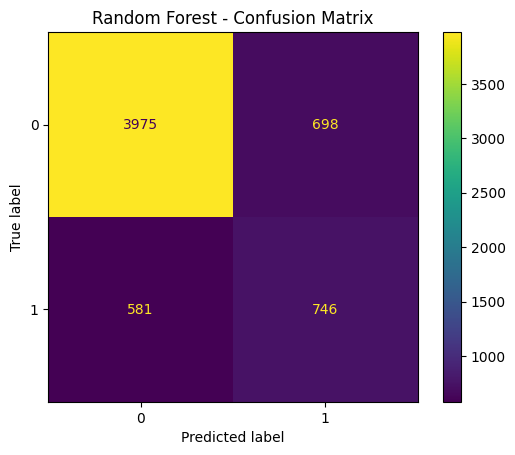

In [34]:
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf
)

disp.plot()
plt.title("Random Forest - Confusion Matrix")
plt.show()

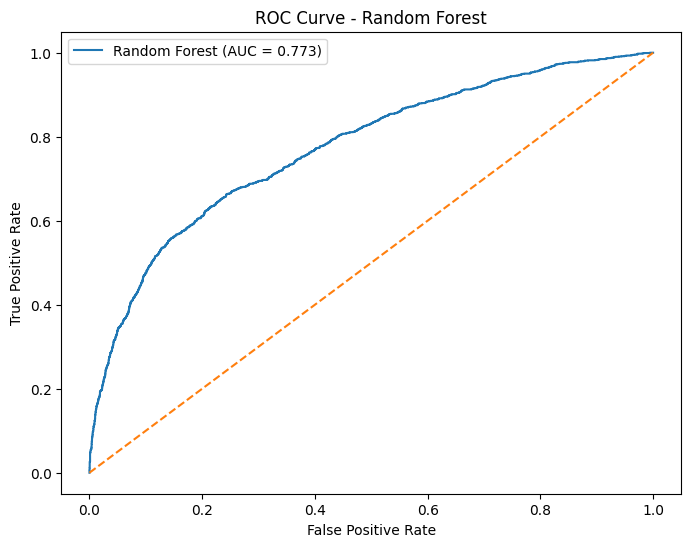

In [35]:
fpr_rf, tpr_rf, _ = roc_curve(
    y_test,
    y_prob_rf
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr_rf,
    tpr_rf,
    label=f"Random Forest (AUC = {rf_roc_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Random Forest")
plt.legend()
plt.show()

In [36]:
from sklearn.ensemble import GradientBoostingClassifier

gradient_boosting_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", GradientBoostingClassifier(
        random_state=42
    ))
])

print("Gradient Boosting pipeline created successfully.")

Gradient Boosting pipeline created successfully.


In [37]:
gradient_boosting_params = {
    "model__n_estimators": [100, 200],
    "model__learning_rate": [0.05, 0.1],
    "model__max_depth": [2, 3]
}

print("Gradient Boosting parameter grid:")
print(gradient_boosting_params)

Gradient Boosting parameter grid:
{'model__n_estimators': [100, 200], 'model__learning_rate': [0.05, 0.1], 'model__max_depth': [2, 3]}


In [38]:
gradient_boosting_grid = GridSearchCV(
    estimator=gradient_boosting_pipeline,
    param_grid=gradient_boosting_params,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1,
    verbose=1
)

gradient_boosting_grid.fit(X_train, y_train)

print("\nBest Gradient Boosting Parameters:")
print(gradient_boosting_grid.best_params_)

print("\nBest Cross-Validation ROC-AUC:")
print(gradient_boosting_grid.best_score_)

Fitting 5 folds for each of 8 candidates, totalling 40 fits

Best Gradient Boosting Parameters:
{'model__learning_rate': 0.1, 'model__max_depth': 3, 'model__n_estimators': 100}

Best Cross-Validation ROC-AUC:
0.7815346929208644


In [46]:
best_gradient_boosting_model = gradient_boosting_grid.best_estimator_

print("Best Gradient Boosting model:")
print(best_gradient_boosting_model)

print("\nBest parameters:")
print(gradient_boosting_grid.best_params_)

print("\nBest CV ROC-AUC:")
print(gradient_boosting_grid.best_score_)

Best Gradient Boosting model:
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['X1', 'X5', 'X6', 'X7', 'X8',
                                                   'X9', 'X10', 'X11', 'X12',
                                                   'X13', 'X14', 'X15', 'X16',
                                                   'X17', 'X18', 'X19', 'X20',
                                                   'X21', 'X22', 'X23']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
         

In [47]:
y_pred_gb = best_gradient_boosting_model.predict(X_test)
y_prob_gb = best_gradient_boosting_model.predict_proba(X_test)[:, 1]

gb_accuracy = accuracy_score(y_test, y_pred_gb)
gb_precision = precision_score(y_test, y_pred_gb)
gb_recall = recall_score(y_test, y_pred_gb)
gb_f1 = f1_score(y_test, y_pred_gb)
gb_roc_auc = roc_auc_score(y_test, y_prob_gb)

print("Gradient Boosting Test Results")
print("-------------------------------")
print("Accuracy :", gb_accuracy)
print("Precision:", gb_precision)
print("Recall   :", gb_recall)
print("F1-Score :", gb_f1)
print("ROC-AUC  :", gb_roc_auc)

Gradient Boosting Test Results
-------------------------------
Accuracy : 0.8185
Precision: 0.6634615384615384
Recall   : 0.36397889977392617
F1-Score : 0.47007299270072994
ROC-AUC  : 0.7797792510358292


In [48]:
print("Gradient Boosting Classification Report")
print("----------------------------------------")

print(classification_report(
    y_test,
    y_pred_gb
))

Gradient Boosting Classification Report
----------------------------------------
              precision    recall  f1-score   support

         0.0       0.84      0.95      0.89      4673
         1.0       0.66      0.36      0.47      1327

    accuracy                           0.82      6000
   macro avg       0.75      0.66      0.68      6000
weighted avg       0.80      0.82      0.80      6000



In [49]:
cm_gb = confusion_matrix(
    y_test,
    y_pred_gb
)

print("Gradient Boosting Confusion Matrix:")
print(cm_gb)



Gradient Boosting Confusion Matrix:
[[4428  245]
 [ 844  483]]


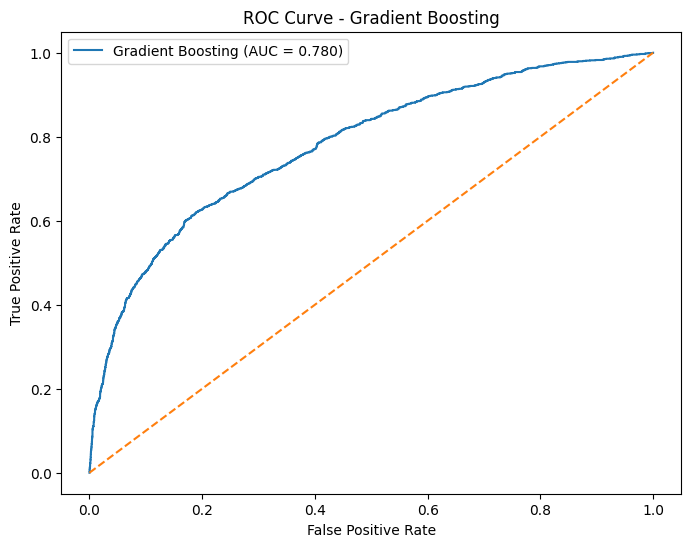

In [50]:
fpr_gb, tpr_gb, _ = roc_curve(
    y_test,
    y_prob_gb
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr_gb,
    tpr_gb,
    label=f"Gradient Boosting (AUC = {gb_roc_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Gradient Boosting")
plt.legend()
plt.show()

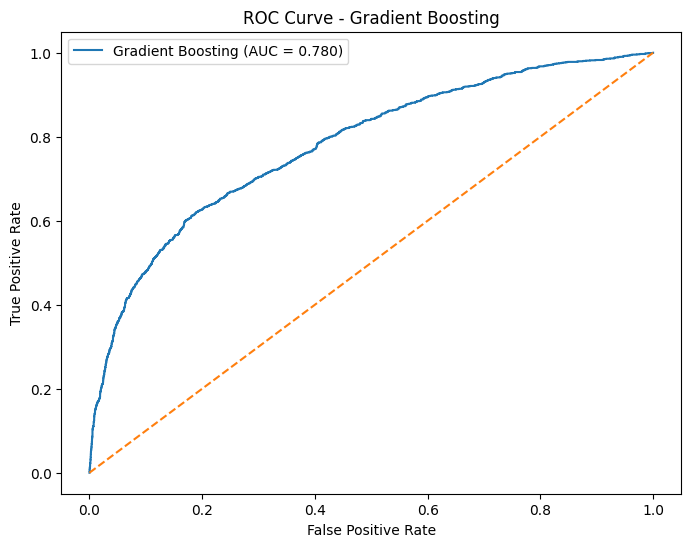

In [51]:
fpr_gb, tpr_gb, _ = roc_curve(
    y_test,
    y_prob_gb
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr_gb,
    tpr_gb,
    label=f"Gradient Boosting (AUC = {gb_roc_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Gradient Boosting")
plt.legend()
plt.show()

In [52]:
hist_gradient_params = {
    "model__max_iter": [100, 200],
    "model__learning_rate": [0.05, 0.1],
    "model__max_leaf_nodes": [15, 31]
}

print("HistGradientBoosting parameter grid:")
print(hist_gradient_params)

HistGradientBoosting parameter grid:
{'model__max_iter': [100, 200], 'model__learning_rate': [0.05, 0.1], 'model__max_leaf_nodes': [15, 31]}


In [56]:
from sklearn.ensemble import HistGradientBoostingClassifier

hist_gradient_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", HistGradientBoostingClassifier(
        random_state=42
    ))
])

print("HistGradientBoosting pipeline created successfully.")

HistGradientBoosting pipeline created successfully.


In [57]:
hist_gradient_params = {
    "model__max_iter": [100, 200],
    "model__learning_rate": [0.05, 0.1],
    "model__max_leaf_nodes": [15, 31]
}

print("HistGradientBoosting parameter grid:")
print(hist_gradient_params)

HistGradientBoosting parameter grid:
{'model__max_iter': [100, 200], 'model__learning_rate': [0.05, 0.1], 'model__max_leaf_nodes': [15, 31]}


In [58]:
from sklearn.model_selection import GridSearchCV

hist_gradient_grid = GridSearchCV(
    estimator=hist_gradient_pipeline,
    param_grid=hist_gradient_params,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1,
    verbose=1
)

hist_gradient_grid.fit(X_train, y_train)

print("\nBest HistGradientBoosting Parameters:")
print(hist_gradient_grid.best_params_)

print("\nBest Cross-Validation ROC-AUC:")
print(hist_gradient_grid.best_score_)

Fitting 5 folds for each of 8 candidates, totalling 40 fits

Best HistGradientBoosting Parameters:
{'model__learning_rate': 0.05, 'model__max_iter': 200, 'model__max_leaf_nodes': 31}

Best Cross-Validation ROC-AUC:
0.7831121231906801


In [59]:
best_hist_gradient_model = hist_gradient_grid.best_estimator_

print("Best HistGradientBoosting model:")
print(best_hist_gradient_model)

print("\nBest parameters:")
print(hist_gradient_grid.best_params_)

print("\nBest CV ROC-AUC:")
print(hist_gradient_grid.best_score_)

Best HistGradientBoosting model:
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['X1', 'X5', 'X6', 'X7', 'X8',
                                                   'X9', 'X10', 'X11', 'X12',
                                                   'X13', 'X14', 'X15', 'X16',
                                                   'X17', 'X18', 'X19', 'X20',
                                                   'X21', 'X22', 'X23']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
      

In [60]:
y_pred_hgb = best_hist_gradient_model.predict(X_test)

y_prob_hgb = best_hist_gradient_model.predict_proba(X_test)[:, 1]

hgb_accuracy = accuracy_score(y_test, y_pred_hgb)
hgb_precision = precision_score(y_test, y_pred_hgb)
hgb_recall = recall_score(y_test, y_pred_hgb)
hgb_f1 = f1_score(y_test, y_pred_hgb)
hgb_roc_auc = roc_auc_score(y_test, y_prob_hgb)

print("HistGradientBoosting Test Results")
print("----------------------------------")
print("Accuracy :", hgb_accuracy)
print("Precision:", hgb_precision)
print("Recall   :", hgb_recall)
print("F1-Score :", hgb_f1)
print("ROC-AUC  :", hgb_roc_auc)

HistGradientBoosting Test Results
----------------------------------
Accuracy : 0.8175
Precision: 0.6571815718157181
Recall   : 0.3654860587792012
F1-Score : 0.46973365617433416
ROC-AUC  : 0.777050932008358


In [61]:
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "Gradient Boosting",
        "HistGradientBoosting"
    ],
    "Accuracy": [
        logistic_accuracy,
        rf_accuracy,
        gb_accuracy,
        hgb_accuracy
    ],
    "Precision": [
        logistic_precision,
        rf_precision,
        gb_precision,
        hgb_precision
    ],
    "Recall": [
        logistic_recall,
        rf_recall,
        gb_recall,
        hgb_recall
    ],
    "F1-Score": [
        logistic_f1,
        rf_f1,
        gb_f1,
        hgb_f1
    ],
    "ROC-AUC": [
        logistic_roc_auc,
        rf_roc_auc,
        gb_roc_auc,
        hgb_roc_auc
    ]
})

results = results.sort_values(
    by="ROC-AUC",
    ascending=False
).reset_index(drop=True)

display(results)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Gradient Boosting,0.818500,0.663462,0.363979,0.470073,0.779779
1,HistGradientBoosting,0.817500,0.657182,0.365486,0.469734,0.777051
2,Random Forest,0.786833,0.516620,0.562170,0.538434,0.772745
3,Logistic Regression,0.678333,0.367821,0.632253,0.465078,0.710600


In [62]:
best_model_name = results.iloc[0]["Model"]

print("Model selected based on highest ROC-AUC:")
print(best_model_name)

Model selected based on highest ROC-AUC:
Gradient Boosting


NameError: name 'fpr_hgb' is not defined

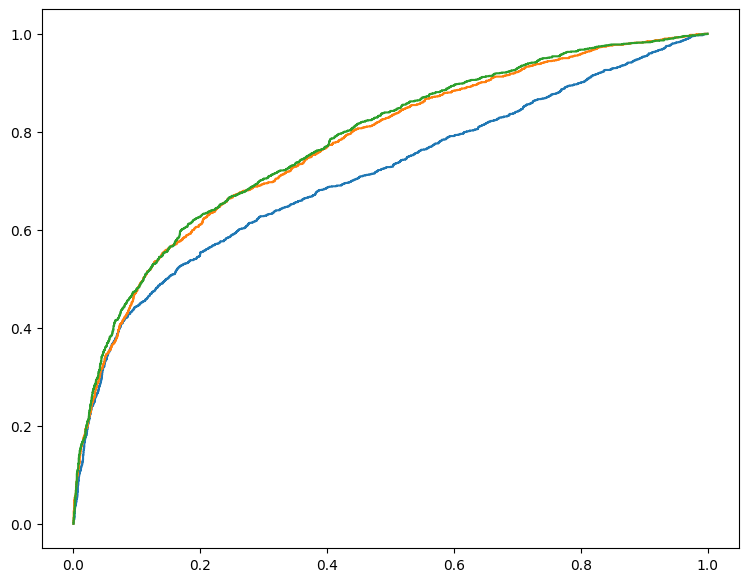

In [63]:
plt.figure(figsize=(9, 7))

plt.plot(
    fpr_logistic,
    tpr_logistic,
    label=f"Logistic Regression (AUC = {logistic_roc_auc:.3f})"
)

plt.plot(
    fpr_rf,
    tpr_rf,
    label=f"Random Forest (AUC = {rf_roc_auc:.3f})"
)

plt.plot(
    fpr_gb,
    tpr_gb,
    label=f"Gradient Boosting (AUC = {gb_roc_auc:.3f})"
)

plt.plot(
    fpr_hgb,
    tpr_hgb,
    label=f"HistGradientBoosting (AUC = {hgb_roc_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC-AUC Comparison of All Models")
plt.legend()
plt.show()

In [64]:
model_dictionary = {
    "Logistic Regression": best_logistic_model,
    "Random Forest": best_random_forest_model,
    "Gradient Boosting": best_gradient_boosting_model,
    "HistGradientBoosting": best_hist_gradient_model
}

champion_model = model_dictionary[best_model_name]

print("Champion model:")
print(champion_model)

Champion model:
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['X1', 'X5', 'X6', 'X7', 'X8',
                                                   'X9', 'X10', 'X11', 'X12',
                                                   'X13', 'X14', 'X15', 'X16',
                                                   'X17', 'X18', 'X19', 'X20',
                                                   'X21', 'X22', 'X23']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                       

In [65]:
joblib.dump(
    champion_model,
    "champion_credit_default_model.pkl"
)

print("Champion model saved successfully!")

Champion model saved successfully!


In [66]:
import os

model_file = "champion_credit_default_model.pkl"

print("Model file exists:", os.path.exists(model_file))

if os.path.exists(model_file):
    print("File size:", os.path.getsize(model_file), "bytes")

Model file exists: True
File size: 144509 bytes


# Conclusion

Four supervised classification models were trained and compared for credit default prediction:

1. Logistic Regression
2. Random Forest
3. Gradient Boosting
4. HistGradientBoosting

Hyperparameter optimization was performed using GridSearchCV with stratified 5-fold cross-validation.

The models were evaluated using:

- Accuracy
- Precision
- Recall
- F1-Score
- ROC-AUC
- Confusion Matrix
- ROC-AUC curves

A model comparison table was created using the test-set evaluation metrics.

The champion model was selected automatically based on the highest ROC-AUC.

The selected model was serialized as a `.pkl` file for reproducibility and potential future deployment.

The complete workflow provides a reproducible supervised machine learning pipeline for credit default risk prediction.